# Detecção de Evasão no Ensino Superior

Este notebook apresenta, de forma estática, um MVP para identificar estudantes com risco de evasão. A análise compara três momentos de previsão: **matrícula**, **após o 1º semestre** e **após o 2º semestre**.

As três trajetórias são mantidas no alvo: `Dropout` (evasão), `Graduate` (conclusão) e `Enrolled` (matriculado).

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42
DATA_PATH = Path("data") / "data.csv"
if not DATA_PATH.exists():
    DATA_PATH = Path("..") / "data" / "data.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH, sep=";")
df.columns = df.columns.str.replace("\t", " ", regex=False).str.strip()
nomes_variaveis_pt = {
    "Marital status": "Estado civil",
    "Application mode": "Modalidade de ingresso",
    "Application order": "Ordem de ingresso",
    "Course": "Curso",
    "Daytime/evening attendance": "Turno (diurno/noturno)",
    "Previous qualification": "Qualificação anterior",
    "Previous qualification (grade)": "Nota da qualificação anterior",
    "Nacionality": "Nacionalidade",
    "Mother's qualification": "Qualificação da mãe",
    "Father's qualification": "Qualificação do pai",
    "Mother's occupation": "Ocupação da mãe",
    "Father's occupation": "Ocupação do pai",
    "Admission grade": "Nota de admissão",
    "Displaced": "Aluno deslocado",
    "Educational special needs": "Necessidades educacionais especiais",
    "Debtor": "Devedor",
    "Tuition fees up to date": "Mensalidades em dia",
    "Gender": "Gênero",
    "Scholarship holder": "Bolsista",
    "Age at enrollment": "Idade na matrícula",
    "International": "Estudante internacional",
    "Curricular units 1st sem (credited)": "Unidades curriculares 1º sem. (creditadas)",
    "Curricular units 1st sem (enrolled)": "Unidades curriculares 1º sem. (matriculadas)",
    "Curricular units 1st sem (evaluations)": "Unidades curriculares 1º sem. (avaliadas)",
    "Curricular units 1st sem (approved)": "Unidades curriculares 1º sem. (aprovadas)",
    "Curricular units 1st sem (grade)": "Nota média 1º semestre",
    "Curricular units 1st sem (without evaluations)": "Unidades curriculares 1º sem. (sem avaliação)",
    "Curricular units 2nd sem (credited)": "Unidades curriculares 2º sem. (creditadas)",
    "Curricular units 2nd sem (enrolled)": "Unidades curriculares 2º sem. (matriculadas)",
    "Curricular units 2nd sem (evaluations)": "Unidades curriculares 2º sem. (avaliadas)",
    "Curricular units 2nd sem (approved)": "Unidades curriculares 2º sem. (aprovadas)",
    "Curricular units 2nd sem (grade)": "Nota média 2º semestre",
    "Curricular units 2nd sem (without evaluations)": "Unidades curriculares 2º sem. (sem avaliação)",
    "Unemployment rate": "Taxa de desemprego",
    "Inflation rate": "Taxa de inflação",
    "GDP": "PIB",
    "Alvo": "Evasão"
}
print(f"Dimensões originais: {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Colunas normalizadas: {list(df.columns)}")

Dimensões originais: 4424 linhas x 37 colunas
Colunas normalizadas: ['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', '

### Comentário sobre a leitura da base

- **O que foi feito:** o arquivo `data.csv` foi carregado, os nomes das colunas foram padronizados e o tamanho da base foi exibido.
- **Por que isso foi feito:** a padronização evita erros ao acessar colunas, enquanto as dimensões confirmam se os dados foram lidos corretamente.
- **Conclusão:** a base possui **4.424 registros e 37 colunas** e está pronta para as próximas etapas.

In [4]:
if "Target" not in df.columns:
    raise KeyError("A coluna obrigatória 'Target' não foi encontrada.")

df = df.loc[df["Target"].isin(["Dropout", "Graduate", "Enrolled"])].copy()
df["Alvo"] = df["Target"].map({"Graduate": 0, "Dropout": 1, "Enrolled": 2}).astype("int8")
df = df.drop(columns="Target")

features_matricula = [
    col for col in df.columns
    if col not in ["Alvo"] and "1st sem" not in col.lower() and "2nd sem" not in col.lower()
]
features_1o_semestre = [
    col for col in df.columns
    if col != "Alvo" and "2nd sem" not in col.lower()
]
features_2o_semestre = [col for col in df.columns if col != "Alvo"]

cenarios = {
    "Matrícula": features_matricula,
    "1º semestre": features_1o_semestre,
    "2º semestre": features_2o_semestre,
}

print(f"Registros definitivos: {len(df)}")
contagem_alvos = df["Alvo"].value_counts().reindex([1, 0, 2])
print(f"Evasão: {contagem_alvos[1]} | Conclusão: {contagem_alvos[0]} | Matriculado: {contagem_alvos[2]}")
for nome, features in cenarios.items():
    print(f"{nome}: {len(features)} variáveis")

Registros definitivos: 4424
Evasão: 1421 | Conclusão: 2209 | Matriculado: 794
Matrícula: 24 variáveis
1º semestre: 30 variáveis
2º semestre: 36 variáveis


### Comentário sobre a preparação dos dados

- **O que foi feito:** o alvo foi convertido para três classes — `0` (conclusão), `1` (evasão) e `2` (matrícula) — e foram criados três cenários de previsão.
- **Por que isso foi feito:** o modelo precisa de uma variável-alvo clara e de conjuntos de atributos compatíveis com o momento em que a previsão seria realizada.
- **Conclusão:** foram mantidos **4.424 estudantes**: **2.209 em conclusão (49,9%)**, **1.421 em evasão (32,1%)** e **794 matriculados (17,9%)**. Quanto mais informações do semestre estão disponíveis, mais variáveis podem ser usadas.

## 1. Dashboard estático: visão geral da base

Os gráficos abaixo são gerados no próprio notebook e constituem uma apresentação estática dos resultados.

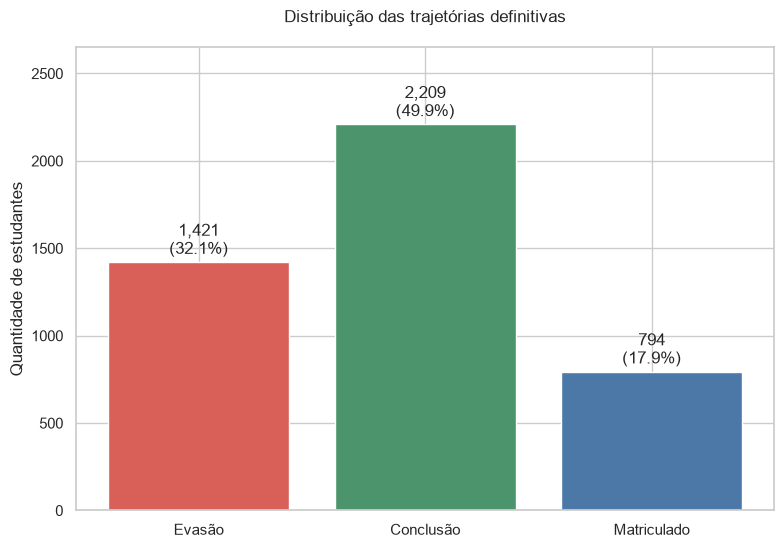

,Quantidade,Percentual (%)
Alvo,,
Evasão,1421,32.12
Conclusão,2209,49.93
Matriculado,794,17.95


In [13]:
contagem = df["Alvo"].map({1: "Evasão", 0: "Conclusão", 2: "Matriculado"}).value_counts().reindex(["Evasão", "Conclusão", "Matriculado"])
percentual = contagem / contagem.sum() * 100

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(contagem.index, contagem.values, color=["#d95f59", "#4c956c", "#4c78a8"])
ax.set_title("Distribuição das trajetórias definitivas", pad=18)
ax.set_ylabel("Quantidade de estudantes")
ax.set_xlabel("")
ax.set_ylim(0, contagem.max() * 1.20)
for bar, qtd, pct in zip(bars, contagem, percentual):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 20,
            f"{qtd:,}\n({pct:.1f}%)", ha="center", va="bottom")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

pd.DataFrame({"Quantidade": contagem, "Percentual (%)": percentual.round(2)})

### Comentário sobre a distribuição do alvo

- **O que foi feito:** a quantidade e o percentual de estudantes em evasão, conclusão e matrícula foram calculados e apresentados em gráficos.
- **Por que isso foi feito:** conhecer o equilíbrio das classes ajuda a interpretar os modelos e evita conclusões baseadas apenas na classe mais frequente.
- **Conclusão:** conclusão é a classe mais frequente, seguida por evasão e matrícula. Como as classes têm tamanhos diferentes, as métricas ponderadas e as matrizes de confusão devem ser analisadas em conjunto.

## 2. Correlações no cenário do 1º semestre

A correlação é usada como análise exploratória, não como prova de causalidade. Variáveis com maior associação devem ser interpretadas junto com o contexto acadêmico.

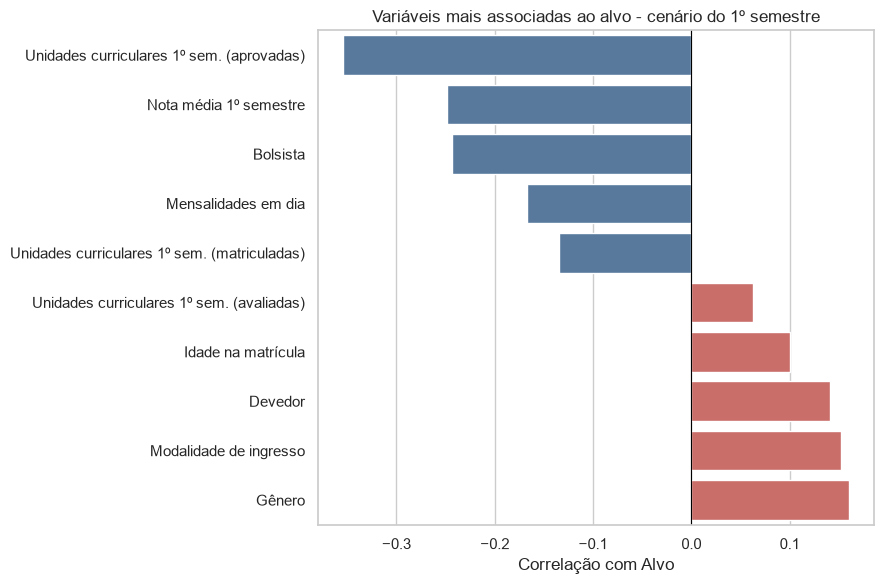

Notas e aprovações são o maior sinal de risco: menos aprovação, mais evasão. 
Mensalidade em dia e bolsa protegem o aluno: quem tem os dois evade menos. 
Perfil do aluno (idade, gênero, estado civil) tem efeito fraco.


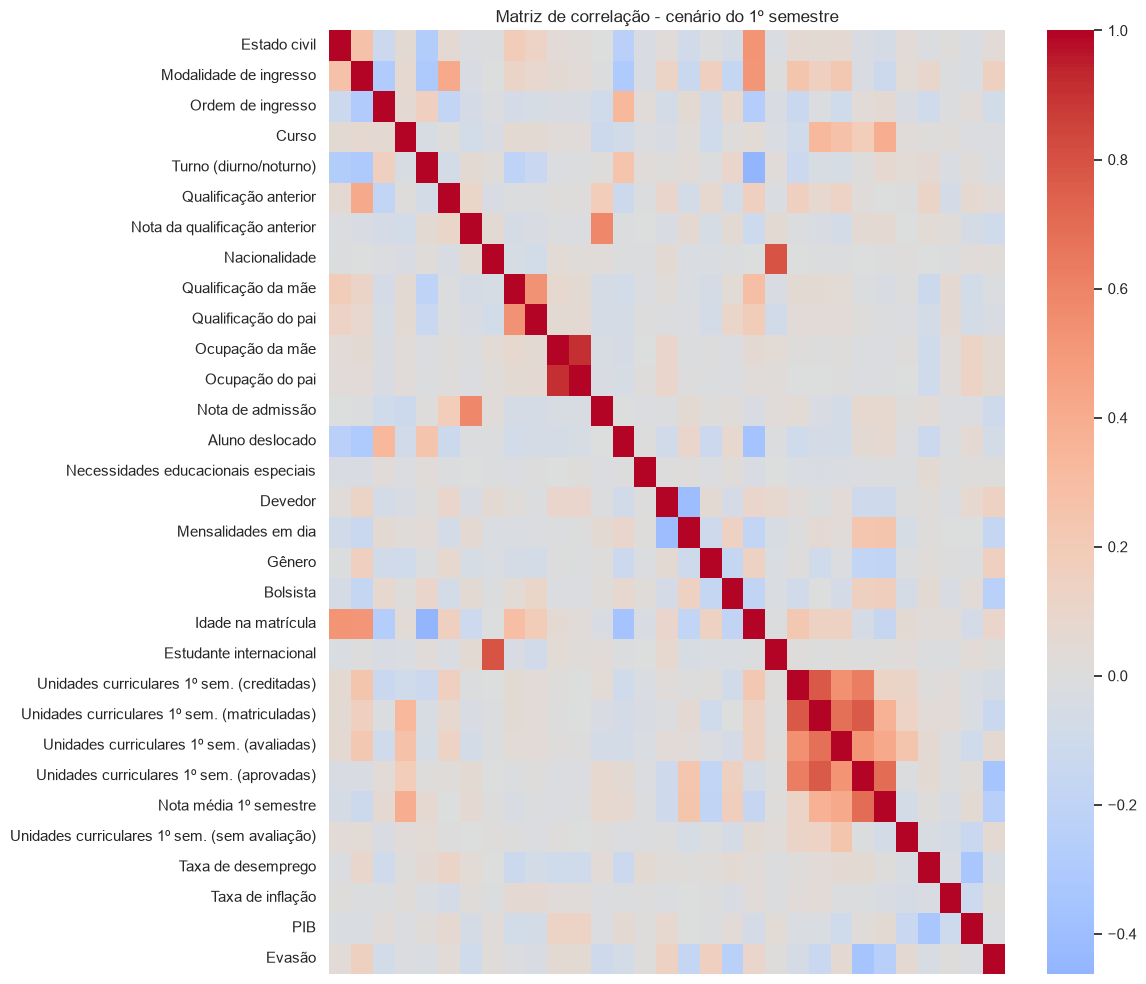

In [6]:
correlacoes = df[features_1o_semestre + ["Alvo"]].corr(numeric_only=True)["Alvo"].drop("Alvo").sort_values()
top_correlacoes = pd.concat([correlacoes.head(5), correlacoes.tail(5)]).sort_values()
top_correlacoes.index = top_correlacoes.index.map(nomes_variaveis_pt)

plt.figure(figsize=(9, 6))
sns.barplot(x=top_correlacoes.values, y=top_correlacoes.index,
            hue=top_correlacoes.values > 0, legend=False,
            palette={True: "#d95f59", False: "#4c78a8"})
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Variáveis mais associadas ao alvo - cenário do 1º semestre")
plt.xlabel("Correlação com Alvo")
plt.ylabel("")
plt.tight_layout()
plt.show()

print(f"As unidades aprovadas e a nota média do 1º semestre estão entre as associações mais fortes com o alvo codificado. \nMensalidade em dia e bolsa também aparecem entre as associações observadas. \nEsses resultados são exploratórios e não determinam, sozinhos, a trajetória do estudante.")

plt.figure(figsize=(12, 10))
matriz_correlacao = df[features_1o_semestre + ["Alvo"]].corr(numeric_only=True)
matriz_correlacao.index = matriz_correlacao.index.map(nomes_variaveis_pt)
sns.heatmap(matriz_correlacao,
            cmap="coolwarm", center=0, xticklabels=False, yticklabels=True)
plt.title("Matriz de correlação - cenário do 1º semestre")
plt.tight_layout()
plt.show()

### Comentário sobre as correlações

- **O que foi feito:** foram selecionadas as variáveis mais positiva e negativamente associadas ao alvo numérico codificado no cenário do 1º semestre, além da matriz completa de correlação.
- **Por que isso foi feito:** essa análise exploratória ajuda a identificar sinais relevantes antes da modelagem.
- **Conclusão:** o maior valor absoluto aparece nas unidades curriculares do 1º semestre aprovadas (-0,354), seguido pela nota média do semestre (-0,248). Como a correlação usa códigos numéricos para três classes, ela não identifica sozinha qual trajetória foi afetada; **correlação não prova causa**.

## 3. Treinamento e avaliação

O conjunto de teste é estratificado e o `StandardScaler` é ajustado somente nos dados de treino. O `class_weight='balanced'` aumenta a atenção dada às classes menos frequentes.

### Como funciona cada modelo

- **Regressão Logística:** calcula a probabilidade de o estudante pertencer a cada uma das três classes usando uma combinação das variáveis. É parecida com uma regra de pontuação para distinguir conclusão, evasão e matrícula.
- **Árvore de Decisão:** faz perguntas sequenciais sobre os dados, como “as notas estão abaixo de certo valor?”. Cada resposta leva a um novo ramo até chegar à previsão final.
- **Random Forest:** combina várias árvores de decisão treinadas com diferentes amostras e variáveis. A previsão final é a decisão mais votada entre as árvores, o que tende a aumentar a estabilidade do resultado.

### O que significa cada score

- **Precision (precisão):** mede, para cada classe, quantas previsões daquela classe estavam corretas. A tabela apresenta a média ponderada pelo número de estudantes em cada classe.
- **Recall (sensibilidade):** mede, para cada classe, quantos estudantes daquela classe foram encontrados pelo modelo. A média ponderada resume as três trajetórias, dando mais peso às classes maiores.
- **F1-score:** combina precision e recall em uma única média. Neste notebook, o F1 apresentado é ponderado e deve ser complementado pela matriz de confusão.

Neste projeto, a matriz de confusão permite avaliar separadamente a identificação de evasão, conclusão e matrícula. O desempenho da classe de evasão continua importante para orientar ações preventivas.

In [7]:
modelos = {
    "Regressão Logística": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
    "Árvore de Decisão": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE, max_depth=8),
    "Random Forest": RandomForestClassifier(class_weight="balanced", n_estimators=300,
                                              random_state=RANDOM_STATE, n_jobs=-1),
}

resultados = []
artefatos = {}
y = df["Alvo"]

for nome_cenario, features in cenarios.items():
    X = df[features].apply(pd.to_numeric, errors="raise")
    X_treino, X_teste, y_treino, y_teste = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
    )
    scaler = StandardScaler()
    X_treino_escalado = scaler.fit_transform(X_treino)
    X_teste_escalado = scaler.transform(X_teste)

    for nome_modelo, modelo_base in modelos.items():
        modelo = modelo_base.__class__(**modelo_base.get_params())
        modelo.fit(X_treino_escalado, y_treino)
        previsoes = modelo.predict(X_teste_escalado)
        resultados.append({
            "Cenário": nome_cenario,
            "Modelo": nome_modelo,
            "Precision (média ponderada)": precision_score(y_teste, previsoes, average="weighted", zero_division=0),
            "Recall (média ponderada)": recall_score(y_teste, previsoes, average="weighted", zero_division=0),
            "F1 (média ponderada)": f1_score(y_teste, previsoes, average="weighted", zero_division=0),
        })
        artefatos[(nome_cenario, nome_modelo)] = {
            "modelo": modelo, "features": features, "y_teste": y_teste,
            "previsoes": previsoes, "matriz": confusion_matrix(y_teste, previsoes),
        }

resultados_df = pd.DataFrame(resultados).sort_values(["Cenário", "F1 (média ponderada)"], ascending=[True, False])
resultados_df.style.format({
"Precision (média ponderada)": "{:.3f}", "Recall (média ponderada)": "{:.3f}", "F1 (média ponderada)": "{:.3f}"
})

,Cenário,Modelo,Precision (média ponderada),Recall (média ponderada),F1 (média ponderada)
5,1º semestre,Random Forest,0.730,0.725,0.727
3,1º semestre,Regressão Logística,0.742,0.694,0.711
4,1º semestre,Árvore de Decisão,0.716,0.629,0.654
8,2º semestre,Random Forest,0.785,0.780,0.782
6,2º semestre,Regressão Logística,0.762,0.727,0.740
7,2º semestre,Árvore de Decisão,0.730,0.689,0.704
2,Matrícula,Random Forest,0.612,0.616,0.614
0,Matrícula,Regressão Logística,0.606,0.526,0.553
1,Matrícula,Árvore de Decisão,0.608,0.514,0.539


### Comentário sobre o treinamento dos modelos

- **O que foi feito:** diferentes modelos foram treinados e avaliados nos três cenários: matrícula, 1º semestre e 2º semestre.
- **Por que isso foi feito:** comparar modelos e momentos de previsão mostra quando a instituição consegue identificar melhor o risco de evasão.
- **Conclusão:** no cenário de matrícula, o Random Forest obteve F1 ponderado de **0,614**, contra **0,553** da Regressão Logística e **0,539** da Árvore. No 1º semestre, o Random Forest alcançou **0,727**; no 2º semestre, chegou a **0,782**, o melhor resultado geral.

,Cenário,Modelo,Precision (média ponderada),Recall (média ponderada),F1 (média ponderada)
5,1º semestre,Random Forest,0.729976,0.725151,0.727287
3,1º semestre,Regressão Logística,0.741979,0.694277,0.711192
4,1º semestre,Árvore de Decisão,0.715991,0.628765,0.653614
8,2º semestre,Random Forest,0.784720,0.780120,0.782034
6,2º semestre,Regressão Logística,0.761765,0.726657,0.739997
7,2º semestre,Árvore de Decisão,0.729867,0.689006,0.703934
2,Matrícula,Random Forest,0.612349,0.615964,0.614093
0,Matrícula,Regressão Logística,0.605999,0.526355,0.552543
1,Matrícula,Árvore de Decisão,0.608192,0.513554,0.539245


,Precision (média ponderada),Recall (média ponderada),F1 (média ponderada)
Cenário,,,
1º semestre,0.741979,0.694277,0.711192
2º semestre,0.761765,0.726657,0.739997
Matrícula,0.605999,0.526355,0.552543


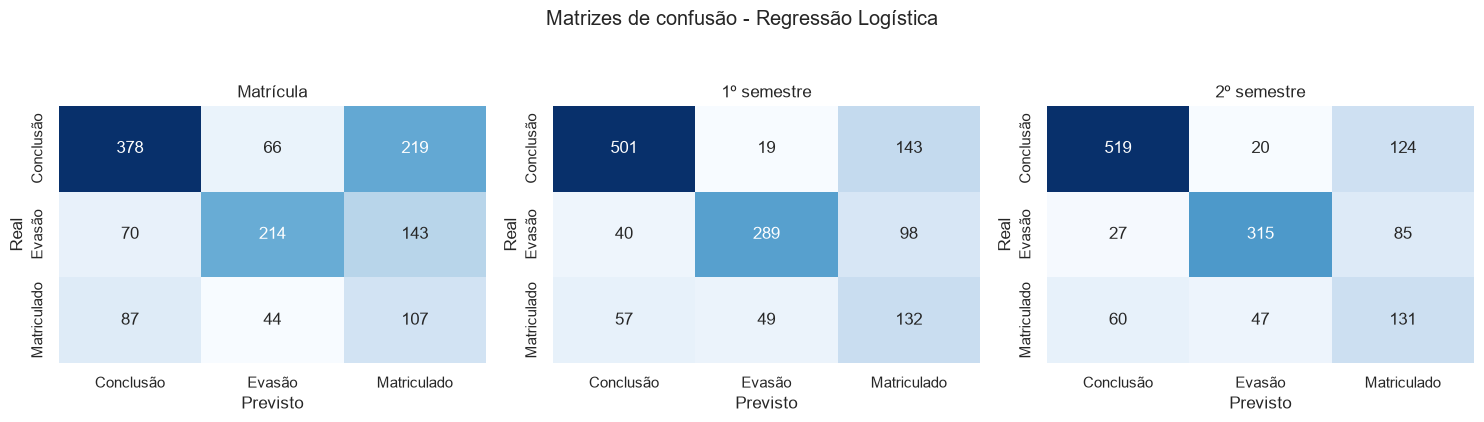

,Precision (média ponderada),Recall (média ponderada),F1 (média ponderada)
Cenário,,,
1º semestre,0.715991,0.628765,0.653614
2º semestre,0.729867,0.689006,0.703934
Matrícula,0.608192,0.513554,0.539245


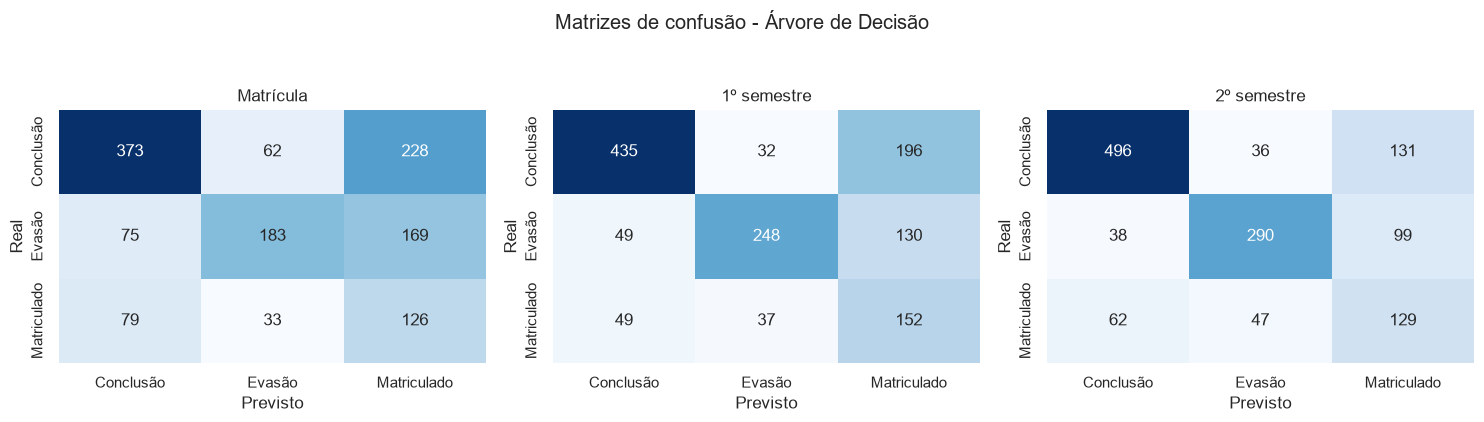

,Precision (média ponderada),Recall (média ponderada),F1 (média ponderada)
Cenário,,,
1º semestre,0.729976,0.725151,0.727287
2º semestre,0.784720,0.780120,0.782034
Matrícula,0.612349,0.615964,0.614093


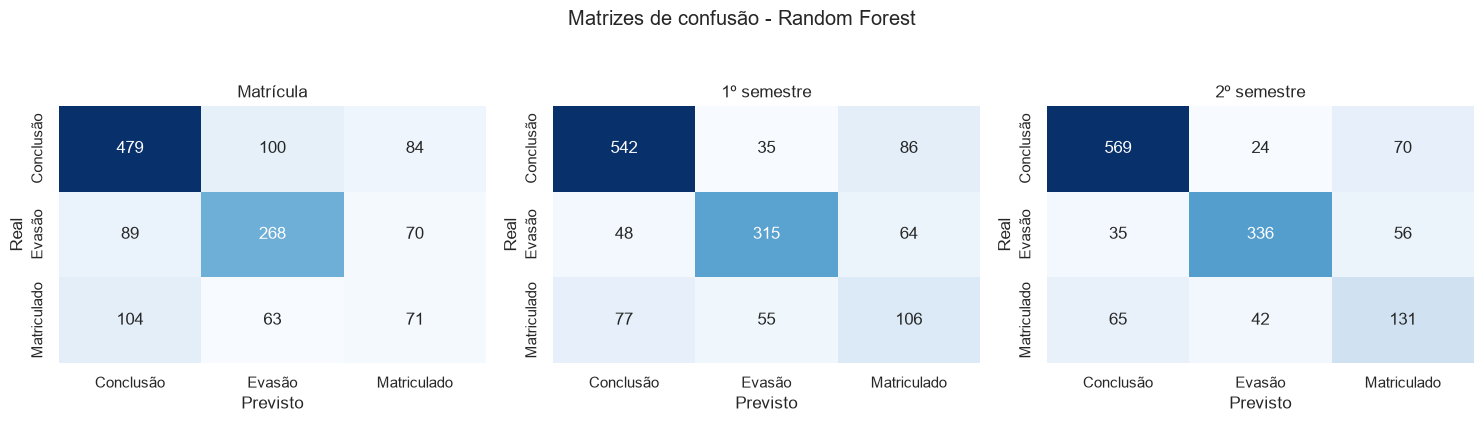

In [8]:
rf_resultados = resultados_df[resultados_df["Modelo"] == "Random Forest"].set_index("Cenário")
display(resultados_df)

for nome_modelo in modelos:
    modelo_resultados = resultados_df[resultados_df["Modelo"] == nome_modelo].set_index("Cenário")
    display(modelo_resultados[["Precision (média ponderada)", "Recall (média ponderada)", "F1 (média ponderada)"]])

    fig, axes = plt.subplots(1, len(cenarios), figsize=(5 * len(cenarios), 4), squeeze=False)
    for ax, nome_cenario in zip(axes[0], cenarios):
        matriz = artefatos[(nome_cenario, nome_modelo)]["matriz"]
        sns.heatmap(
            matriz,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            ax=ax,
            xticklabels=["Conclusão", "Evasão", "Matriculado"],
            yticklabels=["Conclusão", "Evasão", "Matriculado"],
        )
        ax.set_title(nome_cenario)
        ax.set_xlabel("Previsto")
        ax.set_ylabel("Real")
    fig.suptitle(f"Matrizes de confusão - {nome_modelo}", y=1.05)
    plt.tight_layout()
    plt.show()

### Comentário sobre os modelos

- **O que foi feito:** foram exibidas as métricas e as matrizes de confusão de cada modelo e cenário.
- **Por que isso foi feito:** as matrizes mostram os acertos e erros de cada modelo entre evasão, conclusão e matrícula.
- **Conclusão:** o cenário do 2º semestre foi o melhor para os três modelos, com o Random Forest apresentando o maior F1 ponderado (**0,782**). Isso indica que as informações acadêmicas acumuladas ajudam a distinguir as três trajetórias, embora ainda existam confusões entre classes.

## 4. Explicabilidade e conclusão

A importância das variáveis indica quais informações mais contribuíram para as decisões do Random Forest no cenário do 1º semestre. Isso apoia a priorização de ações da coordenação, mas não substitui a avaliação humana do estudante.

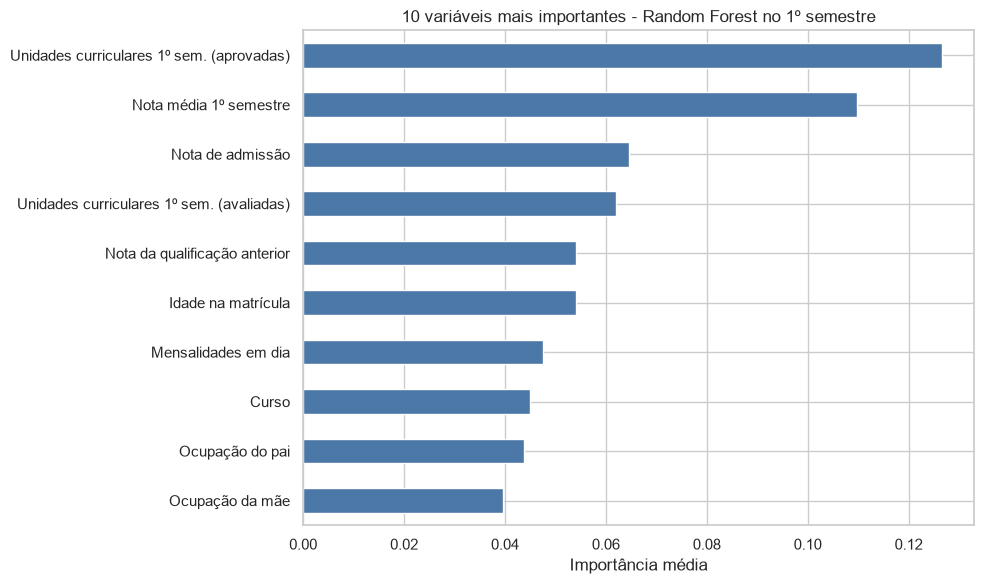

Melhor F1 médio ponderado do Random Forest: 2º semestre (0.782)

Interpretação: a matriz de confusão permite observar separadamente os acertos e erros para evasão, conclusão e matrícula.


In [9]:
artefato_rf = artefatos[("1º semestre", "Random Forest")]
importancias = pd.Series(artefato_rf["modelo"].feature_importances_, index=artefato_rf["features"])
importancias = importancias.sort_values(ascending=False).head(10).sort_values()
importancias.index = importancias.index.map(nomes_variaveis_pt)

plt.figure(figsize=(10, 6))
importancias.plot(kind="barh", color="#4c78a8")
plt.title("10 variáveis mais importantes - Random Forest no 1º semestre")
plt.xlabel("Importância média")
plt.ylabel("")
plt.tight_layout()
plt.show()

melhor = rf_resultados["F1 (média ponderada)"].idxmax()
print(f"Melhor F1 médio ponderado do Random Forest: {melhor} ({rf_resultados.loc[melhor, 'F1 (média ponderada)']:.3f})")
print("\nInterpretação: a matriz de confusão permite observar separadamente os acertos e erros para evasão, conclusão e matrícula.")

### Comentário sobre a explicabilidade e a conclusão

- **O que foi feito:** foram listadas as dez variáveis mais importantes para o Random Forest no cenário do 1º semestre e destacado o melhor F1 médio ponderado entre os cenários.
- **Por que isso foi feito:** entender os fatores usados pelo modelo facilita a análise pela coordenação e ajuda a priorizar ações de acompanhamento.
- **Conclusão:** no cenário do 1º semestre, as maiores importâncias foram unidades curriculares aprovadas (**0,127**), nota média do semestre (**0,110**) e nota de admissão (**0,065**). Elas indicam onde investigar, mas não determinam sozinhas a causa de uma trajetória; o modelo deve apoiar, e não substituir, a avaliação humana.